# Informe – Introducción a los biopotenciales y adquisición de señales ECG y EMG
**Bioseñales y sistemas · Bioingeniería · Facultad de Ingeniería · Universidad de Antioquia**

Este cuaderno desarrolla la **sección 5 (Informe)** de la práctica, usando los registros adquiridos en el laboratorio con el SHIELD-EKG-EMG de Olimex + Arduino UNO:

| Archivo | Señal | Columnas |
|---|---|---|
| `EKG.txt` | ECG en reposo (~60 s) | `Tiempo_s`, `ADC` (10 bits), `Voltaje_V` |
| `EMG.txt` | sEMG en brazo (~20 s) | `Tiempo_s`, `ADC` (10 bits), `Voltaje_V` |

> Los archivos `.txt` deben estar en la misma carpeta que este cuaderno.

In [1]:
# Si hace falta, instalar las librerías (descomentar):
# !pip install neurokit2 py-ecg-detectors hrv-analysis
# Nota: si 'py-ecg-detectors' falla al instalar la dependencia 'gatspy', usar:
# !pip install --no-deps py-ecg-detectors

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from scipy.interpolate import interp1d
from scipy.signal import find_peaks

import neurokit2 as nk
from ecgdetectors import Detectors
from hrvanalysis import get_time_domain_features, remove_outliers, interpolate_nan_values

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

ecg_df = pd.read_csv("EKG.txt", sep="\t")
emg_df = pd.read_csv("EMG.txt", sep="\t")
print("ECG:", ecg_df.shape, "| EMG:", emg_df.shape)
ecg_df.head()

ECG: (780, 3) | EMG: (318, 3)


,Tiempo_s,ADC,Voltaje_V
0,0.001,501,2.449
1,0.001,502,2.454
2,0.002,508,2.483
3,0.002,495,2.419
4,0.002,496,2.424


## 5.1 Etapas del registro de biopotenciales

El registro de un biopotencial es una cadena de transducción y acondicionamiento que va desde la membrana celular hasta un número almacenado en el computador. El esquema siguiente resume las etapas; debajo se explica cada una.

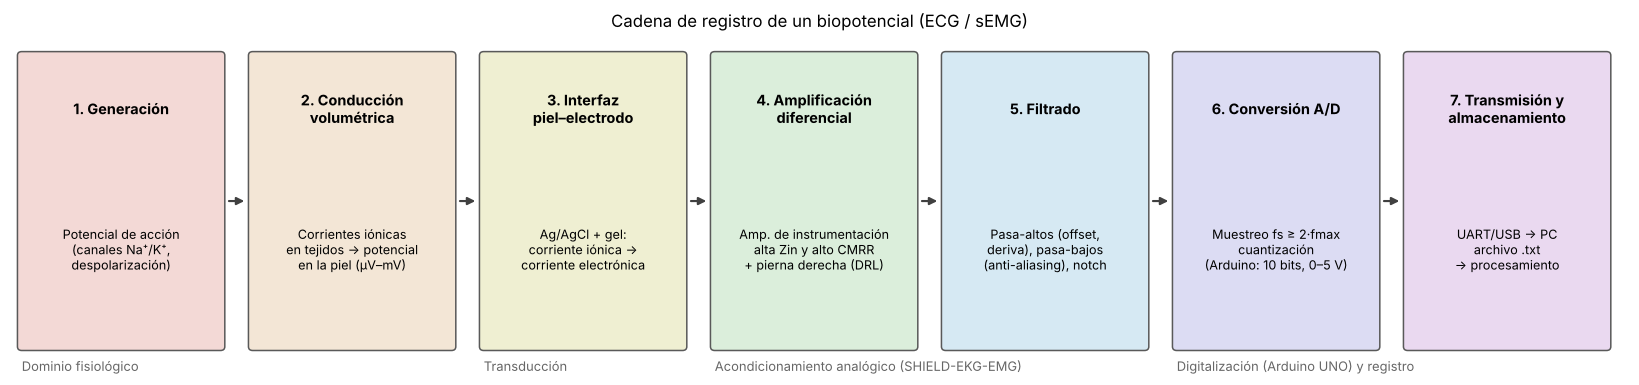

In [3]:
etapas = [
    ("1. Generación", "Potencial de acción\n(canales Na⁺/K⁺,\ndespolarización)"),
    ("2. Conducción\nvolumétrica", "Corrientes iónicas\nen tejidos → potencial\nen la piel (µV–mV)"),
    ("3. Interfaz\npiel–electrodo", "Ag/AgCl + gel:\ncorriente iónica →\ncorriente electrónica"),
    ("4. Amplificación\ndiferencial", "Amp. de instrumentación\nalta Zin y alto CMRR\n+ pierna derecha (DRL)"),
    ("5. Filtrado", "Pasa-altos (offset,\nderiva), pasa-bajos\n(anti-aliasing), notch"),
    ("6. Conversión A/D", "Muestreo fs ≥ 2·fmax\ncuantización\n(Arduino: 10 bits, 0–5 V)"),
    ("7. Transmisión y\nalmacenamiento", "UART/USB → PC\narchivo .txt\n→ procesamiento"),
]
fig, ax = plt.subplots(figsize=(15, 3.6))
ax.set_xlim(0, len(etapas) * 2.15); ax.set_ylim(0, 3.4); ax.axis("off")
colores = ["#f3d9d6", "#f3e6d6", "#efefd2", "#dbeedb", "#d6e9f3", "#dcdcf3", "#ead9f0"]
for i, ((tit, desc), col) in enumerate(zip(etapas, colores)):
    x = i * 2.15 + 0.1
    ax.add_patch(FancyBboxPatch((x, 0.2), 1.85, 3.0, boxstyle="round,pad=0.04",
                                fc=col, ec="0.35", lw=1))
    ax.text(x + 0.925, 2.65, tit, ha="center", va="center", fontsize=9.5, weight="bold")
    ax.text(x + 0.925, 1.2, desc, ha="center", va="center", fontsize=8.3)
    if i < len(etapas) - 1:
        ax.annotate("", xy=(x + 2.1, 1.7), xytext=(x + 1.9, 1.7),
                    arrowprops=dict(arrowstyle="-|>", color="0.25", lw=1.4))
ax.text(0.1, -0.05, "Dominio fisiológico", fontsize=8.5, color="0.4")
ax.text(4.4, -0.05, "Transducción", fontsize=8.5, color="0.4")
ax.text(6.55, -0.05, "Acondicionamiento analógico (SHIELD-EKG-EMG)", fontsize=8.5, color="0.4")
ax.text(10.85, -0.05, "Digitalización (Arduino UNO) y registro", fontsize=8.5, color="0.4")
plt.title("Cadena de registro de un biopotencial (ECG / sEMG)", fontsize=11)
plt.tight_layout(); plt.show()

**1. Generación del potencial de acción.** En las células excitables (miocitos cardíacos, fibras musculares esqueléticas, neuronas) la membrana mantiene un potencial de reposo de aproximadamente −70 a −90 mV por el gradiente iónico que sostiene la bomba Na⁺/K⁺. Ante un estímulo supraumbral se abren canales de Na⁺ (y de Ca²⁺ en el miocardio) y la membrana se despolariza; luego la salida de K⁺ la repolariza. En el corazón el impulso nace en el nodo sinoauricular y se propaga por aurículas, nodo AV, haz de His y fibras de Purkinje; en el músculo esquelético el potencial viaja por el axón motor, cruza la placa neuromuscular y recorre la fibra en ambos sentidos.

**2. Conducción volumétrica.** La propagación del frente de despolarización genera corrientes iónicas que fluyen por los tejidos (que se comportan como un conductor volumétrico). Su efecto en la superficie de la piel es una diferencia de potencial muy pequeña: del orden de 0,5–4 mV para el ECG y de 50 µV a 5 mV para el sEMG, atenuada y filtrada pasa-bajos por el tejido interpuesto.

**3. Interfaz piel–electrodo.** El electrodo (típicamente Ag/AgCl con gel electrolítico) convierte la corriente iónica del cuerpo en corriente electrónica en el cable mediante la reacción reversible Ag ⇌ Ag⁺ + e⁻ / Ag⁺ + Cl⁻ ⇌ AgCl. Es la etapa más crítica (ver 5.3): aporta una impedancia de contacto, un potencial de semicelda y ruido de movimiento.

**4. Amplificación diferencial.** Como la señal es pequeña y está montada sobre una gran tensión de modo común (red eléctrica acoplada al cuerpo), se usa un **amplificador de instrumentación** con impedancia de entrada muy alta (≫ impedancia piel-electrodo) y alto **CMRR**. El circuito de **pierna derecha (DRL)** realimenta el modo común invertido al cuerpo para reducirlo. La ganancia total para ECG/EMG suele ser de 1000–3000.

**5. Filtrado analógico.** Un pasa-altos (≈0,05–0,5 Hz en ECG; 10–20 Hz en sEMG) elimina el offset de electrodo y la deriva de línea base; un pasa-bajos (≈40–150 Hz en ECG; 450–500 Hz en sEMG) cumple de filtro **anti-aliasing**; opcionalmente un notch a 60 Hz. El shield desplaza además la señal a un nivel DC (~2,5 V) para que quepa en el rango 0–5 V del ADC; por eso los registros oscilan alrededor de 2,5 V.

**6. Conversión analógica-digital.** El ADC del Arduino UNO (ATmega328P) es de aproximación sucesiva, **10 bits** sobre 0–5 V, es decir, una resolución de 5/1023 ≈ **4,89 mV por cuenta** (que es la relación `Voltaje_V = ADC·5/1023` en los archivos). La frecuencia de muestreo debe cumplir Nyquist con margen: se recomiendan ≥ 250–500 Hz para ECG y ≥ 1000 Hz para sEMG.

**7. Transmisión, almacenamiento y procesamiento.** Las muestras se envían por puerto serie (UART–USB) al PC, donde se guardan y se procesan digitalmente (filtrado, detección de eventos, extracción de características).

### Componentes de un equipo de adquisición (a grandes rasgos)
- **Electrodos y cables** (preferiblemente apantallados) – transductor e interfaz con el sujeto.
- **Protección y aislamiento** – limitación de corriente, aislamiento galvánico/óptico respecto a la red (seguridad del paciente).
- **Etapa de preamplificación** – amplificador de instrumentación + DRL.
- **Filtros analógicos** – pasa-altos, pasa-bajos anti-aliasing, notch.
- **Amplificación de ganancia y ajuste de offset** – adapta la señal al rango del ADC (en el shield, el potenciómetro de calibración y el nivel de 2,5 V).
- **Conversor A/D y microcontrolador** – muestreo con temporización estable (idealmente por interrupción de temporizador).
- **Interfaz de comunicación y fuente de alimentación** – USB/serie, batería o fuente aislada.
- **Software** – visualización, almacenamiento y procesamiento.

## 5.2 Principales fuentes de ruido en el registro de biopotenciales

| Fuente de ruido | Origen / características | Banda típica | ¿Estática o variante en el tiempo? | Estrategias de control o eliminación |
|---|---|---|---|---|
| **Interferencia de red eléctrica** | Acoplamiento capacitivo e inductivo de la red (60 Hz en Colombia) al cuerpo y a los cables | 60 Hz y armónicos (120, 180 Hz…) | **Estática** (frecuencia fija y amplitud aproximadamente constante mientras no cambie la disposición) | Alto CMRR, circuito DRL, cables apantallados y trenzados, alejar fuentes, alimentación por batería, filtro notch (analógico o digital), filtros adaptativos |
| **Deriva de línea base / respiración** | Cambio de impedancia tórax-electrodo con la respiración, cambios del potencial de semicelda, sudor | < 0,5–1 Hz | **Variante** | Filtro pasa-altos (0,05–0,5 Hz en ECG), splines cúbicos, filtros de mediana, buena preparación de la piel |
| **Artefactos de movimiento** | Desplazamiento del electrodo respecto a la piel, estiramiento de la piel, movimiento de cables | 0,1–10 Hz (se solapa con el ECG) | **Variante** (aleatoria, transitoria) | Reposo del sujeto, fijar cables, electrodos con gel y buena adhesión, abrasión ligera de piel, filtrado adaptativo con acelerómetro, detección y rechazo de segmentos |
| **Ruido electromiográfico (en ECG)** | Actividad de músculos cercanos (pectorales, respiración, temblor) | 20–500 Hz | **Variante** | Sujeto relajado y en posición cómoda, ubicar electrodos sobre zonas óseas, pasa-bajos (≈40 Hz para monitoreo), promediado de latidos |
| **Ruido de contacto / electrodo** | Pérdida parcial de contacto, gel seco, impedancia alta o desbalanceada entre electrodos | Saltos bruscos de línea base y saturación | **Variante** | Verificar impedancia, renovar electrodos y gel, limpiar con alcohol, presión adecuada |
| **Diafonía (cross-talk) en sEMG / ECG en sEMG** | Señal de músculos vecinos; ECG captado en registros de tronco o brazo izquierdo | ECG: 1–40 Hz; EMG vecino: 20–500 Hz | **Variante** | Electrodos pequeños con distancia interelectrodo corta (≈2 cm, recomendación SENIAM), configuración doble diferencial, pasa-altos ≥ 20 Hz, sustracción de plantilla de ECG |
| **Ruido intrínseco de la electrónica** | Ruido térmico (Johnson) y de disparo de resistencias y amplificadores, ruido 1/f | Banda ancha (blanco) y 1/f en bajas frecuencias | **Estática** (estadísticamente estacionario) | Amplificadores de bajo ruido, ganancia alta en la primera etapa, limitar el ancho de banda, promediado |
| **Ruido de cuantización y aliasing** | Resolución finita del ADC (10 bits ≈ 4,9 mV/LSB) y muestreo insuficiente | Plegamiento de componentes por encima de fs/2 | **Estática** (determinada por la configuración) | ADC de mayor resolución, ganancia adecuada para usar todo el rango, filtro anti-aliasing y fs ≥ 2–5 veces la frecuencia máxima, muestreo con temporizador por interrupción |
| **Interferencias electromagnéticas de alta frecuencia** | Equipos de radiofrecuencia, electrobisturí, fuentes conmutadas, celulares | kHz–MHz (pueden demodularse en la entrada) | **Variante** (según los equipos encendidos) | Blindaje, filtros RF en la entrada, separar el equipo de otras fuentes |

**Resumen:** la interferencia de red, el ruido intrínseco de la electrónica y el ruido de cuantización son esencialmente **estáticos** (estacionarios): sus características no cambian durante el registro y se pueden atacar con filtros fijos. La deriva de línea base, los artefactos de movimiento, el ruido muscular, los problemas de contacto y las interferencias externas son **variantes en el tiempo** (no estacionarios), por lo que se controlan sobre todo con buena práctica experimental y, en el procesamiento, con métodos adaptativos o con rechazo de segmentos.

## 5.3 Acoplamiento piel–electrodo

### ¿Cuál es la problemática?
La interfaz piel–electrodo no es un conductor ideal; se modela como un circuito equivalente con:
- **Potencial de semicelda** (E_hc): la reacción electroquímica en la interfaz metal–electrolito genera un potencial DC (≈ +0,22 V para Ag/AgCl). Si los dos electrodos no tienen exactamente el mismo potencial, aparece un **offset diferencial** de hasta cientos de mV que puede saturar el amplificador.
- **Impedancia de la doble capa** (R_d ∥ C_d) en la interfaz electrodo–gel, y la **impedancia de la piel**, dominada por el **estrato córneo** (capa de células muertas, seca y poco conductora): una resistencia en paralelo con una capacitancia que puede ir de unos pocos kΩ (piel preparada) a más de 1 MΩ (piel seca, sin preparar), sobre todo a bajas frecuencias.
- **Ruido** propio de la interfaz y **potenciales de movimiento**: cuando el electrodo se desplaza o la piel se estira, se altera la distribución de cargas de la doble capa y el potencial de la piel, produciendo artefactos de baja frecuencia que se solapan con la señal útil.

Consecuencias prácticas:
1. **Divisor de tensión**: si la impedancia de contacto es comparable con la impedancia de entrada del amplificador, la señal se atenúa.
2. **Conversión de modo común a modo diferencial**: si las impedancias de los dos electrodos están **desbalanceadas**, la tensión de modo común (60 Hz) se convierte en una tensión diferencial que el amplificador ya no puede rechazar, por alto que sea su CMRR.
3. **Saturación y deriva** por el offset de semicelda y su lenta variación.
4. **Artefactos de movimiento**, que no se pueden eliminar completamente con filtros porque comparten banda con el ECG (0,5–10 Hz).

### Estrategias para mejorarlo
- **Preparación de la piel**: limpiar con alcohol para retirar grasa y sudor, abrasión suave para remover el estrato córneo, rasurar si hay vello.
- **Electrodos no polarizables Ag/AgCl** con **gel electrolítico** (húmedo o sólido/hidrogel), que tienen bajo potencial de semicelda, bajo ruido y buena estabilidad.
- **Buena fijación mecánica**: adhesivo, bandas elásticas (como las del EMG), aliviar la tensión de los cables con cinta para minimizar el movimiento.
- **Esperar unos minutos** después de colocar los electrodos para que el gel hidrate la piel y la impedancia se estabilice.
- **Electrónica adecuada**: amplificadores con impedancia de entrada muy alta (≥ 10⁸–10¹² Ω) y alto CMRR, circuito DRL, **electrodos activos** (preamplificador junto al electrodo) y cables apantallados.
- **Verificar la impedancia** antes de registrar (por ejemplo < 5–10 kΩ y similar entre electrodos).
- Para sEMG, seguir las recomendaciones **SENIAM** (tamaño, distancia interelectrodo ≈ 20 mm, orientación paralela a las fibras).

### ¿Por qué es la etapa más crítica en registros de superficie (sEMG, EEG, ECG)?
Porque es el **primer eslabón de la cadena** y todo lo que se degrada allí ya no se puede recuperar después: cualquier ruido, atenuación o artefacto generado en la interfaz entra al amplificador **sumado a la señal y en su misma banda**, de modo que la amplificación lo multiplica igual que a la señal y el filtrado no puede separarlo sin distorsionarla. Además, las señales de superficie son muy pequeñas (µV en EEG, decenas de µV a pocos mV en sEMG y ECG) frente a los potenciales de la interfaz (offset de semicelda de decenas a cientos de mV, artefactos de movimiento de varios mV) y frente a la interferencia de red. Finalmente, la interfaz es **la parte menos controlable y más variable** del sistema: depende del sujeto (tipo y estado de la piel, sudor, vello), de la preparación y del movimiento, y cambia con el tiempo, mientras que la electrónica posterior se diseña una sola vez con especificaciones conocidas. Por eso la **relación señal-ruido final del registro** queda limitada por la calidad del contacto.

## 5.4 Análisis de la variabilidad de la frecuencia cardíaca (HRV)

### 5.4.0 Exploración de los registros y control de calidad
Antes de detectar picos R hay que verificar **cómo fue muestreada la señal**, porque todos los detectores asumen una frecuencia de muestreo `fs` conocida y constante.

In [4]:
def resumen_muestreo(df, nombre):
    t = df["Tiempo_s"].to_numpy()
    dt = np.diff(t)
    burst = dt < 0.01                      # intervalos muy cortos (ráfaga inicial)
    fs_reg = 1 / np.median(dt[~burst])
    return pd.Series({
        "N muestras": len(t),
        "Duración (s)": t[-1] - t[0],
        "Muestras en ráfaga (dt < 10 ms)": int(burst.sum()) + 1,
        "dt mediano régimen (ms)": 1000 * np.median(dt[~burst]),
        "dt desv. est. (ms)": 1000 * np.std(dt[~burst]),
        "fs efectiva (Hz)": fs_reg,
        "Rango V (V)": df["Voltaje_V"].max() - df["Voltaje_V"].min(),
    }, name=nombre)

calidad = pd.concat([resumen_muestreo(ecg_df, "ECG"), resumen_muestreo(emg_df, "EMG")], axis=1)
calidad

,ECG,EMG
N muestras,780.000,318.000
Duración (s),59.924,19.934
Muestras en ráfaga (dt < 10 ms),77.000,83.000
dt mediano régimen (ms),84.767,84.431
dt desv. est. (ms),7.911,12.946
fs efectiva (Hz),11.797,11.844
Rango V (V),0.645,0.543


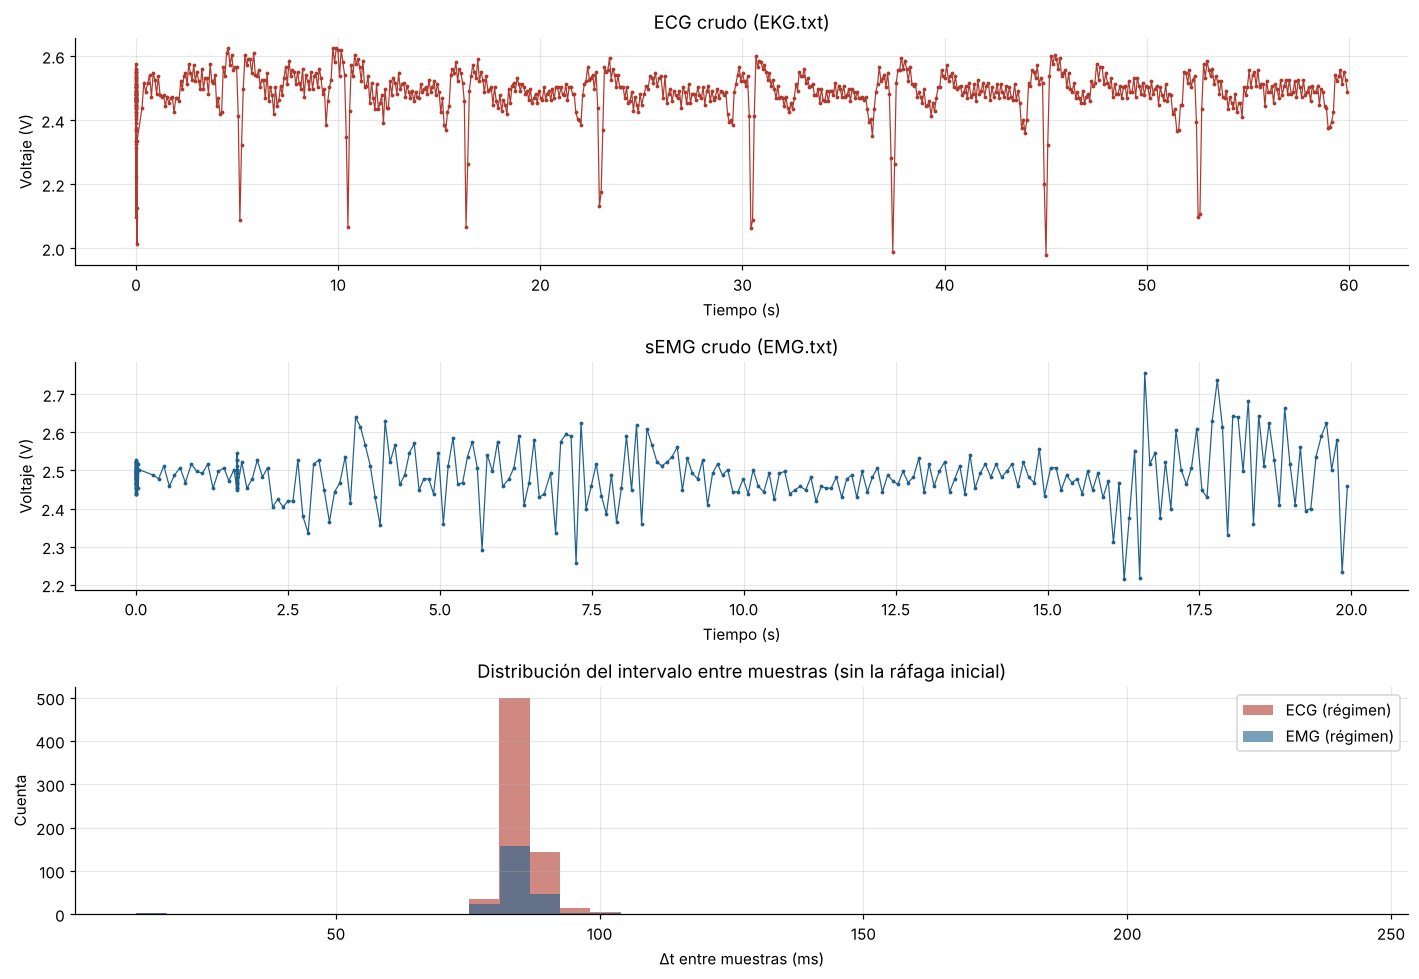

In [5]:
fig, axs = plt.subplots(3, 1, figsize=(13, 9))
axs[0].plot(ecg_df["Tiempo_s"], ecg_df["Voltaje_V"], ".-", ms=3, lw=0.8, color="#b03a2e")
axs[0].set(title="ECG crudo (EKG.txt)", xlabel="Tiempo (s)", ylabel="Voltaje (V)")
axs[1].plot(emg_df["Tiempo_s"], emg_df["Voltaje_V"], ".-", ms=3, lw=0.8, color="#1f618d")
axs[1].set(title="sEMG crudo (EMG.txt)", xlabel="Tiempo (s)", ylabel="Voltaje (V)")
for df, lab, c in [(ecg_df, "ECG", "#b03a2e"), (emg_df, "EMG", "#1f618d")]:
    dt = np.diff(df["Tiempo_s"]) * 1000
    axs[2].hist(dt[dt > 10], bins=40, alpha=0.6, label=f"{lab} (régimen)", color=c)
axs[2].set(title="Distribución del intervalo entre muestras (sin la ráfaga inicial)",
           xlabel="Δt entre muestras (ms)", ylabel="Cuenta"); axs[2].legend()
plt.tight_layout(); plt.show()

**Hallazgo importante – submuestreo.** Los dos archivos tienen una ráfaga inicial de ~60–80 muestras separadas por ~0,05 ms y, después, una muestra cada **≈ 84 ms**, es decir, una frecuencia de muestreo efectiva de **≈ 12 Hz**. La ráfaga corresponde a líneas que estaban acumuladas en el buffer del puerto serie y se leyeron de golpe; el ritmo de ~12 Hz lo impuso el **ciclo de lectura en el PC** (probablemente con graficación en vivo o un `delay`), no el ADC. Así, la columna `Tiempo_s` registra el instante en que el PC leyó cada línea y no el instante real de conversión.

Implicaciones:
- Nyquist exige `fs > 2·fmax`. El complejo QRS tiene contenido hasta ~40 Hz (se recomiendan ≥ 250 Hz) y el sEMG hasta ~450 Hz (≥ 1000 Hz). Con 12 Hz solo se representan componentes por debajo de **6 Hz**: el resto se pierde o aparece **plegado (aliasing)**.
- En el ECG se ven deflexiones negativas marcadas (polaridad invertida por la derivación) separadas por **5–7,5 s**, lo que equivaldría a **8–11 lpm**, fisiológicamente imposible en un sujeto en reposo. Lo que se observa es un efecto estroboscópico: cada muestra cae en una fase distinta del ciclo cardíaco y la morfología aparente es una versión "ralentizada" del latido, no la sucesión real de latidos.

Por esto, el análisis de 5.4 se hace en dos partes: **(a)** con los datos reales del laboratorio, siguiendo el procedimiento pedido y documentando qué tanto se puede concluir; **(b)** con un ECG sintético de referencia (`nk.ecg_simulate`, con picos R conocidos) para responder con fundamento qué detector funciona mejor y para mostrar que la cadena de cálculo de HRV está bien implementada.

Antes de seguir, una mirada rápida al sEMG (aunque la sección 5.4 se centra en el ECG):

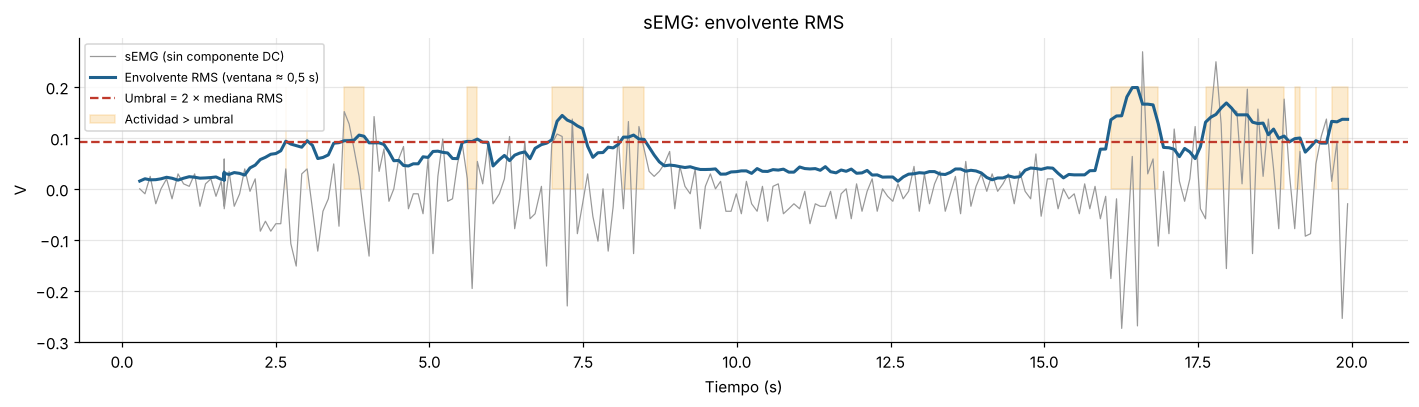

RMS en reposo (mediana): 46.1 mV | RMS máxima: 198.7 mV


In [6]:
t_emg = emg_df["Tiempo_s"].to_numpy(); v_emg = emg_df["Voltaje_V"].to_numpy()
m = t_emg > 0.25                                    # descartar la ráfaga inicial
t_emg, v_emg = t_emg[m], v_emg[m]
v_ac = v_emg - np.median(v_emg)
ventana = 6                                          # ≈ 0,5 s a ~12 Hz
rms = pd.Series(v_ac).rolling(ventana, center=True, min_periods=1).apply(lambda x: np.sqrt(np.mean(x**2)))
umbral = 2 * np.median(rms)

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(t_emg, v_ac, lw=0.8, color="0.6", label="sEMG (sin componente DC)")
ax.plot(t_emg, rms, lw=2, color="#1f618d", label="Envolvente RMS (ventana ≈ 0,5 s)")
ax.axhline(umbral, ls="--", color="#c0392b", label="Umbral = 2 × mediana RMS")
ax.fill_between(t_emg, 0, rms.max(), where=rms > umbral, color="#f5b041", alpha=0.25, label="Actividad > umbral")
ax.set(title="sEMG: envolvente RMS", xlabel="Tiempo (s)", ylabel="V"); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

print(f"RMS en reposo (mediana): {1000*np.median(rms):.1f} mV | RMS máxima: {1000*rms.max():.1f} mV")

La envolvente muestra dos periodos con mayor amplitud (≈ 2–9 s y ≈ 16–20 s) separados por un tramo de reposo, consistentes con contracciones. Sin embargo, el registro dura solo ~20 s (el protocolo pedía diez contracciones de ~1 s) y, a 12 Hz, el sEMG –cuya energía está en 20–450 Hz– aparece completamente plegado: la envolvente sirve como indicio cualitativo de actividad, pero no permite análisis espectral ni de amplitud confiable.

### 5.4.1 Detección de picos R con NeuroKit y con Detectors

**Preprocesamiento del ECG real:**
1. Se descarta la ráfaga inicial (t < 0,25 s).
2. Se invierte la polaridad (el QRS aparece como deflexión negativa en esta derivación).
3. Se interpola (spline cúbico) a una rejilla uniforme de 250 Hz. Esto **no agrega información**; solo es necesario porque los detectores requieren muestreo uniforme y sus filtros están diseñados para `fs` del orden de cientos de Hz (por ejemplo, el notch de 50/60 Hz de NeuroKit no puede existir con `fs = 12 Hz`).
4. Se limpia con `nk.ecg_clean` (pasa-altos de 0,5 Hz + notch) y la misma señal limpia se entrega a todos los detectores para que la comparación sea justa.

**Referencia:** como no hay anotaciones de un experto, se toma como referencia los eventos tipo QRS evidentes en las **muestras crudas** (mínimos con prominencia > 0,2 V). Un detector se considera correcto si marca un pico a menos de 0,3 s de un evento de referencia (≈ 3,5 periodos de muestreo).

In [7]:
# --- Señal real: preprocesamiento ---
FS = 250
ecg_r = ecg_df[ecg_df["Tiempo_s"] > 0.25]
t_raw, v_raw = ecg_r["Tiempo_s"].to_numpy(), ecg_r["Voltaje_V"].to_numpy()
t_u = np.arange(t_raw[0], t_raw[-1], 1 / FS)
ecg_u = -interp1d(t_raw, v_raw, kind="cubic")(t_u)          # polaridad invertida
ecg_u = ecg_u - np.median(ecg_u)
ecg_clean = nk.ecg_clean(ecg_u, sampling_rate=FS, method="neurokit")

# --- Referencia: eventos QRS evidentes en las muestras crudas ---
idx_ref, _ = find_peaks(np.median(v_raw) - v_raw, prominence=0.2, distance=20)
t_ref = t_raw[idx_ref]
print("Eventos de referencia (s):", np.round(t_ref, 2))
print("Intervalos entre eventos (s):", np.round(np.diff(t_ref), 2))

Eventos de referencia (s): [ 5.14 10.48 16.33 22.92 30.42 37.43 45.02 52.54]
Intervalos entre eventos (s): [5.35 5.84 6.6  7.49 7.02 7.58 7.53]


In [8]:
METODOS_NK = ["neurokit", "pantompkins1985", "hamilton2002", "christov2004",
              "elgendi2010", "engzeemod2012", "kalidas2017", "nabian2018", "rodrigues2021"]

LIMPIEZA_PROPIA = {"pantompkins1985", "hamilton2002", "elgendi2010", "engzeemod2012"}

def detectar_todos(senal, fs):
    # Devuelve {nombre: índices de picos R} para NeuroKit y Detectors.
    # 'senal' es el ECG sin limpiar (centrado). En NeuroKit cada método recibe la señal
    # limpiada con su propio filtro cuando existe (como lo hace nk.ecg_process);
    # los de Detectors traen su propio filtrado interno y reciben la señal limpia de NeuroKit.
    out = {}
    limpia_nk = nk.ecg_clean(senal, sampling_rate=fs, method="neurokit")
    for m in METODOS_NK:
        try:
            x = nk.ecg_clean(senal, sampling_rate=fs, method=m) if m in LIMPIEZA_PROPIA else limpia_nk
            _, info = nk.ecg_peaks(x, sampling_rate=fs, method=m)
            out[f"NeuroKit · {m}"] = np.asarray(info["ECG_R_Peaks"], dtype=int)
        except Exception as e:
            print(f"NeuroKit {m}: error ({e})")
    det = Detectors(fs)
    for nombre, f in [("pan_tompkins", det.pan_tompkins_detector), ("hamilton", det.hamilton_detector),
                      ("christov", det.christov_detector), ("engzee", det.engzee_detector),
                      ("swt", det.swt_detector), ("two_average", det.two_average_detector),
                      ("wqrs", det.wqrs_detector)]:
        try:
            out[f"Detectors · {nombre}"] = np.asarray(f(limpia_nk), dtype=int)
        except Exception as e:
            print(f"Detectors {nombre}: error ({e})")
    return out

def evaluar(t_det, t_ref, tol):
    # Empareja cada pico de referencia con a lo sumo un pico detectado dentro de ±tol
    t_det = np.sort(np.asarray(t_det)); usados = np.zeros(len(t_det), bool); tp = 0
    for r in t_ref:
        cand = np.where((np.abs(t_det - r) <= tol) & ~usados)[0]
        if len(cand):
            usados[cand[np.argmin(np.abs(t_det[cand] - r))]] = True; tp += 1
    fp, fn = len(t_det) - tp, len(t_ref) - tp
    return {"Detectados": len(t_det), "VP": tp, "FP": fp, "FN": fn,
            "Sensibilidad": tp / (tp + fn) if tp + fn else np.nan,
            "VPP": tp / (tp + fp) if tp + fp else np.nan,
            "F1": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan}

picos_real = detectar_todos(ecg_u, FS)
tabla_real = pd.DataFrame({k: evaluar(t_u[v], t_ref, tol=0.3) for k, v in picos_real.items()}).T
tabla_real = tabla_real.sort_values("F1", ascending=False)
tabla_real

,Detectados,VP,FP,FN,Sensibilidad,VPP,F1
NeuroKit · neurokit,5.0,4.0,1.0,4.0,0.50,0.800,0.615
NeuroKit · hamilton2002,40.0,8.0,32.0,0.0,1.00,0.200,0.333
NeuroKit · kalidas2017,40.0,8.0,32.0,0.0,1.00,0.200,0.333
Detectors · hamilton,40.0,8.0,32.0,0.0,1.00,0.200,0.333
Detectors · pan_tompkins,49.0,8.0,41.0,0.0,1.00,0.163,0.281
NeuroKit · nabian2018,56.0,8.0,48.0,0.0,1.00,0.143,0.250
NeuroKit · engzeemod2012,10.0,2.0,8.0,6.0,0.25,0.200,0.222
Detectors · engzee,10.0,2.0,8.0,6.0,0.25,0.200,0.222
Detectors · wqrs,65.0,8.0,57.0,0.0,1.00,0.123,0.219
Detectors · swt,78.0,8.0,70.0,0.0,1.00,0.103,0.186


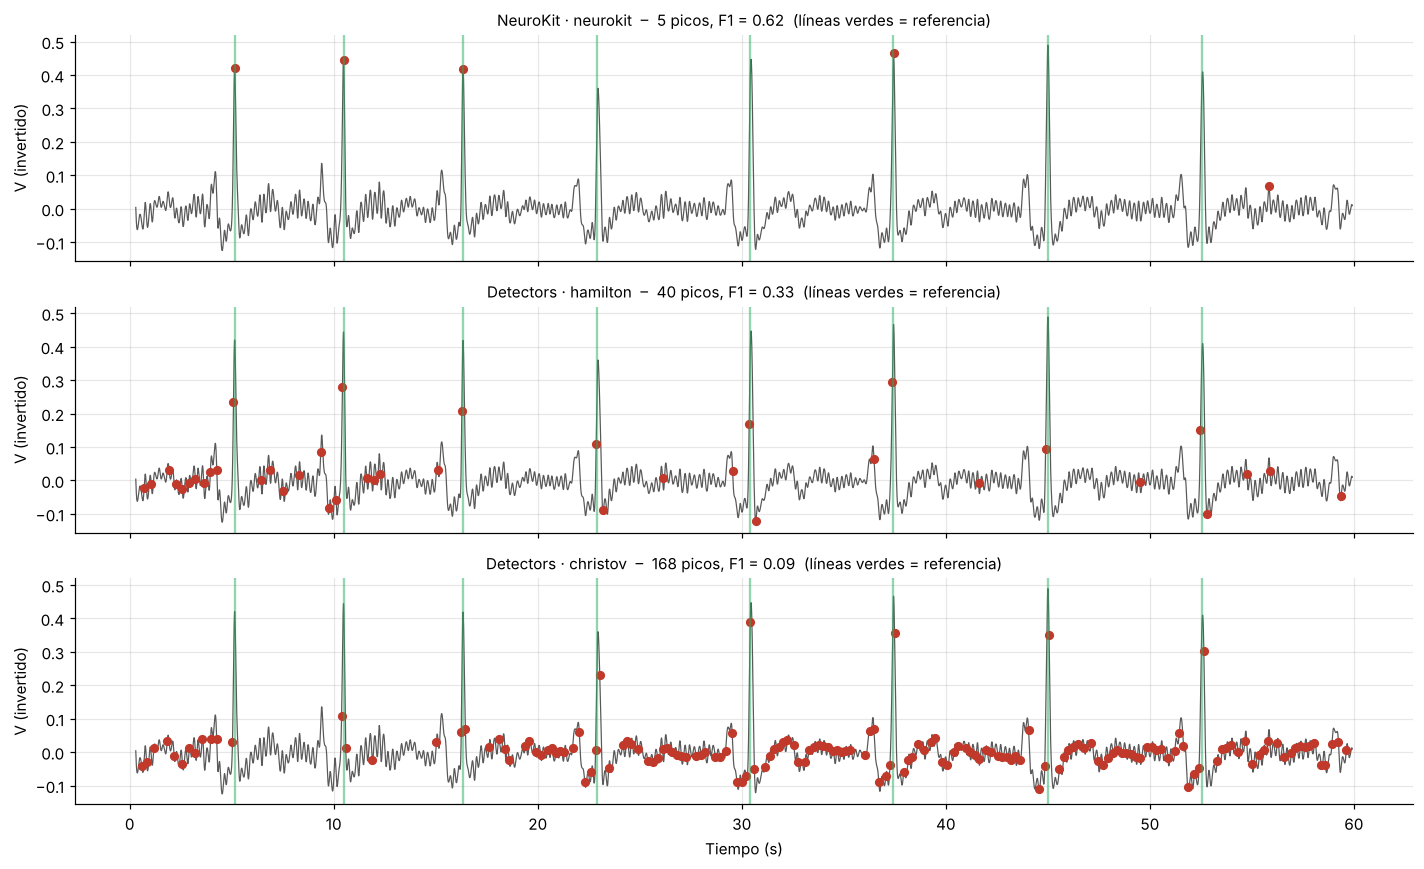

In [9]:
mejor_real = tabla_real.index[0]
mostrar = [mejor_real, "Detectors · hamilton", "Detectors · christov"]
fig, axs = plt.subplots(len(mostrar), 1, figsize=(13, 8), sharex=True)
for ax, k in zip(axs, mostrar):
    ax.plot(t_u, ecg_clean, lw=0.8, color="0.35")
    p = picos_real[k]
    ax.plot(t_u[p], ecg_clean[p], "o", ms=5, color="#c0392b", label="Detectado")
    for r in t_ref:
        ax.axvline(r, color="#27ae60", alpha=0.5, lw=1.5)
    f1 = tabla_real.loc[k, "F1"]
    ax.set_title(f"{k}  –  {len(p)} picos, F1 = {f1:.2f}  (líneas verdes = referencia)", fontsize=10)
    ax.set_ylabel("V (invertido)")
axs[-1].set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()

**Lectura de los resultados con la señal real.** Ningún algoritmo detecta correctamente los eventos de la señal del laboratorio: los que más acercan la cantidad de eventos se pierden muchos, y los que encuentran todos los eventos de referencia también marcan decenas de falsos positivos. No es un problema de los algoritmos, sino de la señal: todos ellos asumen (i) que el QRS tiene energía en la banda 5–25 Hz, que con `fs ≈ 12 Hz` no existe; (ii) periodos refractarios de 200–360 ms y RR fisiológicos (0,3–2 s), mientras que los eventos aparentes están a 5–7,5 s. Los umbrales adaptativos, al no encontrar un latido en el intervalo esperado, se reducen y empiezan a marcar el ruido (de ahí los falsos positivos).

Para responder **cuál algoritmo detecta mejor** en condiciones válidas, se repite la comparación con un ECG sintético de 60 s a 500 Hz (frecuencia media 72 lpm con variabilidad), al que se le añade ruido realista (ruido gaussiano, interferencia de 60 Hz y deriva respiratoria de 0,2 Hz). Los picos verdaderos se obtienen de la misma simulación sin ruido. Tolerancia: ±100 ms.

In [10]:
FS_SIM = 500
kw = dict(duration=60, sampling_rate=FS_SIM, heart_rate=72, heart_rate_std=4, random_state=7)
sim_limpio = nk.ecg_simulate(noise=0, **kw)
t_sim = np.arange(len(sim_limpio)) / FS_SIM
rng = np.random.default_rng(1)
sim_ruido = (nk.ecg_simulate(noise=0.1, **kw)
             + 0.10 * np.sin(2 * np.pi * 60 * t_sim)       # red eléctrica
             + 0.30 * np.sin(2 * np.pi * 0.2 * t_sim)      # deriva respiratoria
             + 0.05 * rng.standard_normal(len(t_sim)))     # ruido de banda ancha

_, info_ref = nk.ecg_peaks(sim_limpio, sampling_rate=FS_SIM)
t_ref_sim = info_ref["ECG_R_Peaks"] / FS_SIM
sim_clean = nk.ecg_clean(sim_ruido, sampling_rate=FS_SIM, method="neurokit")

picos_sim = detectar_todos(sim_ruido, FS_SIM)
tabla_sim = pd.DataFrame({k: evaluar(v / FS_SIM, t_ref_sim, tol=0.10) for k, v in picos_sim.items()}).T
tabla_sim = tabla_sim.sort_values(["F1", "Sensibilidad"], ascending=False)
print(f"Latidos reales en la simulación: {len(t_ref_sim)}")
tabla_sim

Latidos reales en la simulación: 72


,Detectados,VP,FP,FN,Sensibilidad,VPP,F1
NeuroKit · neurokit,72.0,72.0,0.0,0.0,1.000,1.000,1.000
NeuroKit · elgendi2010,72.0,72.0,0.0,0.0,1.000,1.000,1.000
NeuroKit · kalidas2017,72.0,72.0,0.0,0.0,1.000,1.000,1.000
Detectors · two_average,72.0,72.0,0.0,0.0,1.000,1.000,1.000
Detectors · hamilton,73.0,72.0,1.0,0.0,1.000,0.986,0.993
NeuroKit · nabian2018,71.0,71.0,0.0,1.0,0.986,1.000,0.993
Detectors · engzee,71.0,71.0,0.0,1.0,0.986,1.000,0.993
NeuroKit · pantompkins1985,74.0,72.0,2.0,0.0,1.000,0.973,0.986
NeuroKit · rodrigues2021,74.0,72.0,2.0,0.0,1.000,0.973,0.986
Detectors · wqrs,74.0,72.0,2.0,0.0,1.000,0.973,0.986


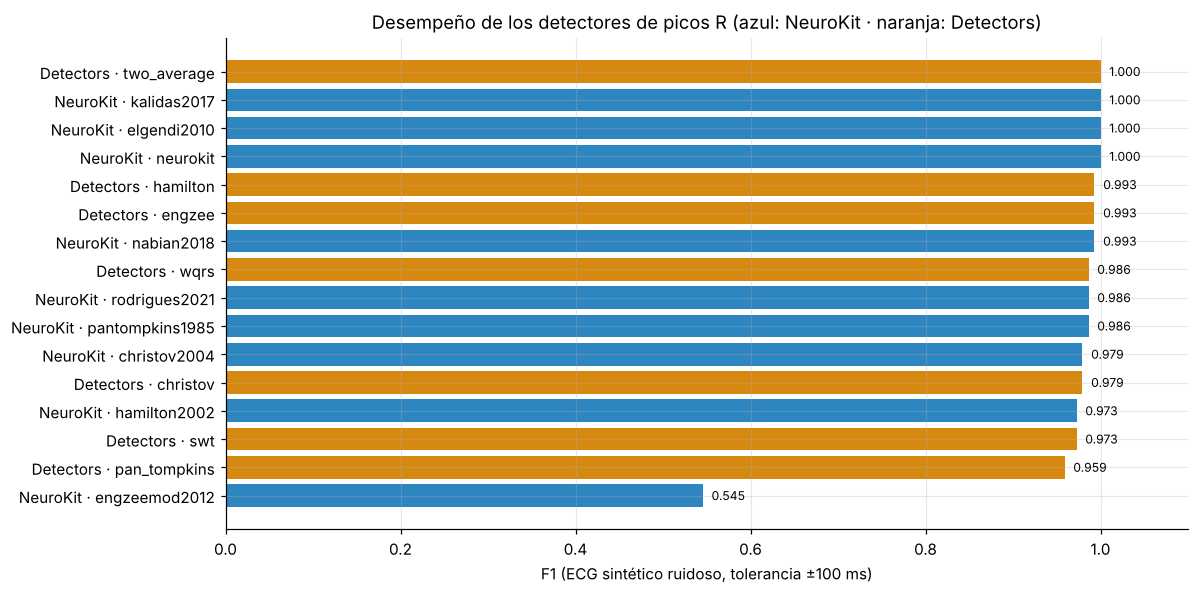

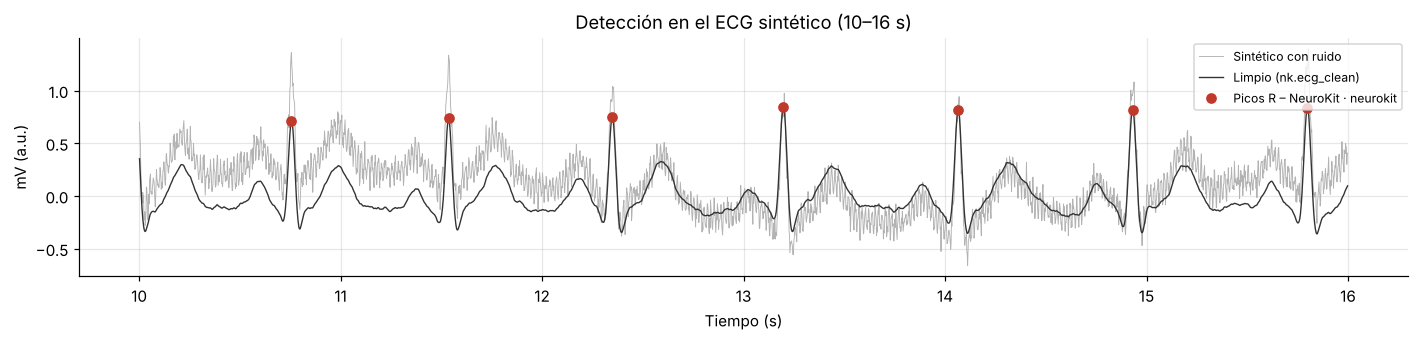

In [11]:
fig, ax = plt.subplots(figsize=(11, 5.5))
orden = tabla_sim["F1"].astype(float).sort_values()
colores = ["#2e86c1" if k.startswith("NeuroKit") else "#d68910" for k in orden.index]
ax.barh(orden.index, orden.values, color=colores)
for i, v in enumerate(orden.values):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=8)
ax.set(xlim=(0, 1.1), xlabel="F1 (ECG sintético ruidoso, tolerancia ±100 ms)",
       title="Desempeño de los detectores de picos R (azul: NeuroKit · naranja: Detectors)")
plt.tight_layout(); plt.show()

seg = (t_sim > 10) & (t_sim < 16)
mejor_sim = tabla_sim.index[0]
p = picos_sim[mejor_sim]; p = p[(p / FS_SIM > 10) & (p / FS_SIM < 16)]
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.plot(t_sim[seg], sim_ruido[seg], lw=0.6, color="0.7", label="Sintético con ruido")
ax.plot(t_sim[seg], sim_clean[seg], lw=0.9, color="0.2", label="Limpio (nk.ecg_clean)")
ax.plot(p / FS_SIM, sim_clean[p], "o", color="#c0392b", label=f"Picos R – {mejor_sim}")
ax.set(xlabel="Tiempo (s)", ylabel="mV (a.u.)", title="Detección en el ECG sintético (10–16 s)")
ax.legend(fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

Para demostrar que el problema de la señal real es la frecuencia de muestreo, el mismo ECG sintético se **remuestrea a 12 Hz** (como en el laboratorio) y se vuelve a interpolar a 250 Hz:

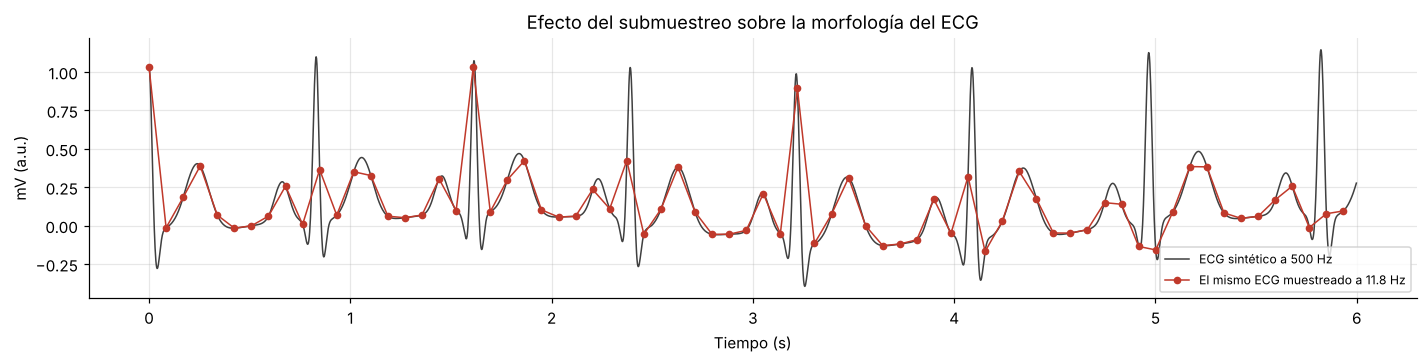

F1 medio a 500 Hz: 0.96  |  F1 medio tras muestrear a 11.8 Hz: 0.49


,Detectados,VP,FP,FN,F1
NeuroKit · neurokit,36.0,36.0,0.0,36.0,0.667
NeuroKit · pantompkins1985,53.0,37.0,16.0,35.0,0.592
NeuroKit · rodrigues2021,90.0,47.0,43.0,25.0,0.580
Detectors · pan_tompkins,57.0,37.0,20.0,35.0,0.574
Detectors · swt,54.0,36.0,18.0,36.0,0.571
NeuroKit · elgendi2010,83.0,39.0,44.0,33.0,0.503
Detectors · two_average,84.0,39.0,45.0,33.0,0.500
NeuroKit · nabian2018,71.0,34.0,37.0,38.0,0.476
Detectors · engzee,103.0,40.0,63.0,32.0,0.457
NeuroKit · engzeemod2012,104.0,40.0,64.0,32.0,0.455


In [12]:
fs_lab = calidad.loc["fs efectiva (Hz)", "ECG"]
t_lab = np.arange(0, 60, 1 / fs_lab)
sim_lab = np.interp(t_lab, t_sim, sim_limpio)                     # "muestreado" a ~12 Hz
t_up = np.arange(t_lab[0], t_lab[-1], 1 / FS)
sim_up = interp1d(t_lab, sim_lab, kind="cubic")(t_up)

fig, ax = plt.subplots(figsize=(13, 3.4))
seg = t_sim < 6
ax.plot(t_sim[seg], sim_limpio[seg], color="0.25", lw=1, label="ECG sintético a 500 Hz")
s2 = t_lab < 6
ax.plot(t_lab[s2], sim_lab[s2], "o-", color="#c0392b", ms=4, lw=1, label=f"El mismo ECG muestreado a {fs_lab:.1f} Hz")
ax.set(xlabel="Tiempo (s)", ylabel="mV (a.u.)", title="Efecto del submuestreo sobre la morfología del ECG")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

sim_up_clean = nk.ecg_clean(sim_up, sampling_rate=FS)
picos_up = detectar_todos(sim_up, FS)
tabla_up = pd.DataFrame({k: evaluar(t_up[v], t_ref_sim, tol=0.10) for k, v in picos_up.items()}).T
print(f"F1 medio a 500 Hz: {tabla_sim['F1'].astype(float).mean():.2f}  |  "
      f"F1 medio tras muestrear a {fs_lab:.1f} Hz: {tabla_up['F1'].astype(float).mean():.2f}")
tabla_up.sort_values("F1", ascending=False)[["Detectados", "VP", "FP", "FN", "F1"]]

### ¿Cuál de los algoritmos detecta mejor los picos R?

- **Con la señal real del laboratorio** no hay un ganador válido: todos los algoritmos fallan (ver tabla de 5.4.1), y la causa es la adquisición a ≈ 12 Hz, no los algoritmos. Lo mismo pasa con la señal sintética cuando se submuestrea a la misma frecuencia.
- **Con un ECG adquirido a una frecuencia adecuada** (sintético a 500 Hz con ruido), casi todos los métodos superan F1 = 0,95. Los únicos con detección perfecta (72/72 latidos, 0 falsos positivos, F1 = 1,00) fueron, en NeuroKit, el método por defecto **`neurokit`**, `elgendi2010` y `kalidas2017`, y en Detectors, **`two_average`**. Les siguen `hamilton`, `engzee` y `nabian2018` (F1 ≈ 0,99). El peor fue `engzeemod2012` de NeuroKit, que omitió 45 de los 72 latidos (F1 ≈ 0,55); en Detectors, `pan_tompkins` y `swt` quedaron últimos (F1 ≈ 0,96–0,97).
- **Respuesta:** el algoritmo con mejor desempeño global es el **método por defecto de NeuroKit (`neurokit`)**: es el único que obtiene el mejor F1 en los tres escenarios (señal real, sintético a 500 Hz y sintético submuestreado), y en la señal real es el que menos falsos positivos produce, aunque solo recupera la mitad de los eventos. Entre los algoritmos de la librería Detectors, el mejor fue `two_average` en la señal sintética y `hamilton` en la señal real.

La tabla y la figura anteriores dan los valores exactos de esta ejecución. Conviene recordar que la evaluación se hizo con un solo registro sintético; un juicio definitivo requiere bases anotadas (p. ej., MIT-BIH) como en el estudio de Porr y Howell (2019).

### 5.4.2 Cálculo de la HRV a partir de los picos R
La HRV se calcula sobre la serie de **intervalos RR** (o NN, "normal-to-normal") en milisegundos: `RR_i = t(R_{i+1}) − t(R_i)`. Se hace primero con el ECG sintético (mejor detector) y luego con los eventos de la señal real.

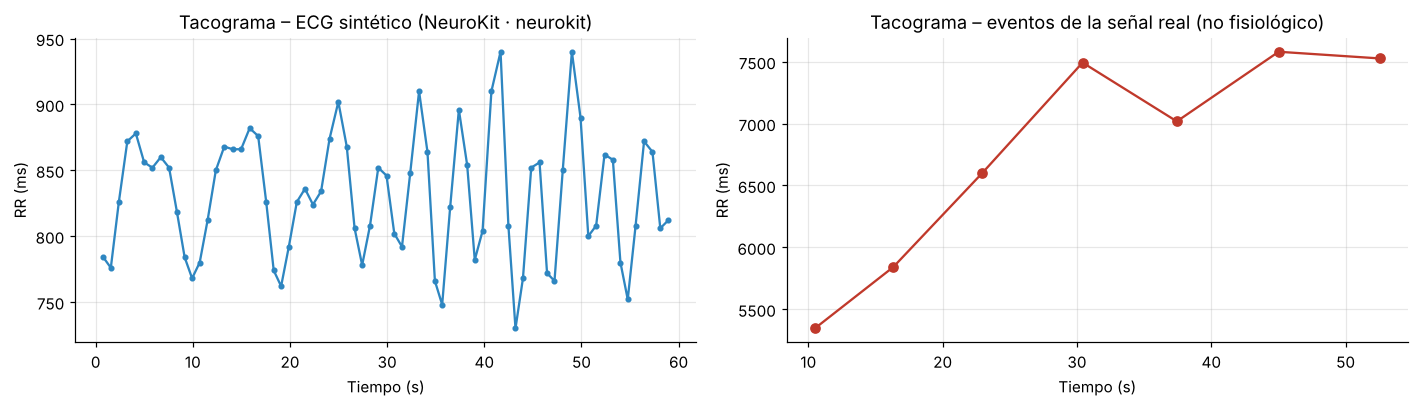

Sintético: 71 intervalos, RR medio = 830 ms → FC = 72.3 lpm
Real:      7 intervalos, RR medio = 6772 ms → FC aparente = 8.9 lpm


In [13]:
def serie_rr(t_picos):
    return np.diff(np.sort(t_picos)) * 1000          # ms

rr_sim = serie_rr(picos_sim[mejor_sim] / FS_SIM)
rr_real = serie_rr(t_ref)                            # eventos tipo QRS de la señal real

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
axs[0].plot(np.cumsum(rr_sim) / 1000, rr_sim, "o-", ms=3, color="#2e86c1")
axs[0].set(title=f"Tacograma – ECG sintético ({mejor_sim})", xlabel="Tiempo (s)", ylabel="RR (ms)")
axs[1].plot(t_ref[1:], rr_real, "o-", color="#c0392b")
axs[1].set(title="Tacograma – eventos de la señal real (no fisiológico)", xlabel="Tiempo (s)", ylabel="RR (ms)")
plt.tight_layout(); plt.show()

print(f"Sintético: {len(rr_sim)} intervalos, RR medio = {rr_sim.mean():.0f} ms → FC = {60000/rr_sim.mean():.1f} lpm")
print(f"Real:      {len(rr_real)} intervalos, RR medio = {rr_real.mean():.0f} ms → FC aparente = {60000/rr_real.mean():.1f} lpm")

In [14]:
# Índices de HRV en el dominio del tiempo con NeuroKit (para contrastar con hrvanalysis)
hrv_nk_sim = nk.hrv_time(picos_sim[mejor_sim], sampling_rate=FS_SIM)
cols = ["HRV_MeanNN", "HRV_SDNN", "HRV_RMSSD", "HRV_SDSD", "HRV_pNN50", "HRV_pNN20", "HRV_CVNN", "HRV_MedianNN"]
hrv_nk_sim[cols]

,HRV_MeanNN,HRV_SDNN,HRV_RMSSD,HRV_SDSD,HRV_pNN50,HRV_pNN20,HRV_CVNN,HRV_MedianNN
0,829.944,47.021,48.836,49.187,29.577,63.38,0.057,826.0


### 5.4.3 Características de HRV en el dominio del tiempo con `hrvanalysis.get_time_domain_features`

La librería `hrvanalysis` recibe una **lista de intervalos NN en ms**. El flujo recomendado es: (1) `remove_outliers` elimina los RR fuera del rango fisiológico (por defecto 300–2000 ms); (2) `interpolate_nan_values` rellena los valores eliminados; (3) `get_time_domain_features` calcula los índices. (La librería también ofrece `remove_ectopic_beats` para latidos ectópicos.)

| Característica | Significado |
|---|---|
| `mean_nni`, `median_nni` | Media y mediana de los intervalos NN (ms) |
| `sdnn` | Desviación estándar de los NN: variabilidad global (simpática + parasimpática) |
| `sdsd` | Desviación estándar de las diferencias entre NN sucesivos |
| `rmssd` | Raíz cuadrática media de las diferencias sucesivas: variabilidad de corto plazo, marcador del tono **vagal** |
| `nni_50`, `pnni_50` | Número y porcentaje de diferencias sucesivas > 50 ms (actividad parasimpática) |
| `nni_20`, `pnni_20` | Ídem con umbral de 20 ms (más sensible en registros cortos) |
| `range_nni` | Diferencia entre el NN máximo y el mínimo |
| `cvnni`, `cvsd` | Coeficientes de variación: `sdnn/mean_nni` y `rmssd/mean_nni` |
| `mean_hr`, `max_hr`, `min_hr`, `std_hr` | Estadísticos de la frecuencia cardíaca instantánea (lpm) |

In [15]:
def hrv_dominio_tiempo(rr_ms, limpiar=True):
    rr = list(rr_ms)
    if limpiar:
        rr = remove_outliers(rr_intervals=rr, low_rri=300, high_rri=2000, verbose=False)
        rr = interpolate_nan_values(rr_intervals=rr, interpolation_method="linear")
    return get_time_domain_features(rr)

feat_sim = hrv_dominio_tiempo(rr_sim)
feat_real = hrv_dominio_tiempo(rr_real, limpiar=False)   # sin limpiar: todos los RR reales están fuera del rango fisiológico

tabla_hrv = pd.DataFrame({"ECG sintético (500 Hz)": feat_sim,
                          "Señal real (eventos aliasados)": feat_real}).astype(float)
tabla_hrv

,ECG sintético (500 Hz),Señal real (eventos aliasados)
mean_nni,829.944,6771.846
sdnn,47.021,888.453
sdsd,48.834,478.143
nni_50,23.000,6.000
pnni_50,32.857,100.000
nni_20,45.000,6.000
pnni_20,64.286,100.000
rmssd,48.836,600.666
median_nni,826.000,7018.137
range_nni,210.000,2235.310


In [16]:
# Si se aplica la limpieza fisiológica a la serie real, todos los intervalos se descartan:
rr_real_filtrado = remove_outliers(rr_intervals=list(rr_real), low_rri=300, high_rri=2000, verbose=False)
print("RR reales tras remove_outliers:", rr_real_filtrado)
print("→ Ningún intervalo de la señal real está en el rango fisiológico (300–2000 ms).")

RR reales tras remove_outliers: [nan, nan, nan, nan, nan, nan, nan]
→ Ningún intervalo de la señal real está en el rango fisiológico (300–2000 ms).


**Interpretación.**
- En el ECG sintético los índices son coherentes con un adulto sano en reposo: FC media ≈ 72 lpm, SDNN y RMSSD en el orden de decenas de ms, pNN50 moderado. Los valores calculados con `hrvanalysis` coinciden con los de `nk.hrv_time`, lo que valida la implementación.
- En la señal real, el "RR medio" de ~6800 ms (≈ 9 lpm) y la SDNN de casi 1 s **no describen la variabilidad del corazón del sujeto**: miden la periodicidad del patrón de aliasing entre el latido y el reloj de lectura. `remove_outliers` descarta el 100 % de los intervalos, lo que confirma que no son RR fisiológicos. Para obtener una HRV válida hay que repetir la adquisición con un muestreo correcto (ver recomendaciones en 5.6).
- Aun con buena adquisición, 1 minuto es corto: las guías de la Task Force (1996) recomiendan registros de **5 min** para los índices de corto plazo y **24 h** para SDNN como indicador global.

## 5.5 Aplicaciones clínicas del ECG y del EMG

### Electrocardiografía (ECG)

| # | Aplicación clínica | Tipo de registro | Procesamiento utilizado |
|---|---|---|---|
| 1 | **Detección de arritmias** (fibrilación auricular, extrasístoles, bloqueos) | ECG ambulatorio **Holter** de 24–48 h (2–3 canales) o monitores/parches de varios días; también relojes inteligentes de una derivación | Filtrado (pasa-banda 0,5–40 Hz), detección de QRS (Pan-Tompkins y derivados), análisis de la irregularidad RR, ausencia de onda P, clasificación de latidos con aprendizaje automático o redes neuronales profundas (Hannun et al., 2019) |
| 2 | **Diagnóstico de isquemia e infarto agudo de miocardio** | ECG de **12 derivaciones** en reposo (fs ≥ 500 Hz, ancho de banda 0,05–150 Hz para no distorsionar el segmento ST) y prueba de esfuerzo | Filtrado de línea base sin distorsión de fase, promediado de latidos, delineación de ondas (P, QRS, T) y medición de la elevación/depresión del segmento ST, ondas Q patológicas (criterios de la Cuarta Definición Universal de Infarto) |
| 3 | **Evaluación autonómica y estratificación de riesgo mediante HRV** (post-infarto, neuropatía diabética, insuficiencia cardíaca) | Holter de 24 h o registros cortos de 5 min en condiciones controladas | Detección de picos R, corrección de latidos ectópicos, índices en el dominio del tiempo (SDNN, RMSSD, pNN50), frecuencia (potencias LF, HF, razón LF/HF) y no lineales (Poincaré, entropía). Una SDNN reducida se asocia con mayor mortalidad tras un infarto (Kleiger et al., 1987) |

### Electromiografía (EMG)

| # | Aplicación clínica | Tipo de registro | Procesamiento utilizado |
|---|---|---|---|
| 1 | **Diagnóstico de enfermedades neuromusculares** (miopatías, neuropatías, ELA, radiculopatías) | **EMG de aguja** (intramuscular), fs ≈ 10–20 kHz, en reposo y con contracción voluntaria; complementada con estudios de conducción nerviosa | Análisis de los potenciales de unidad motora (amplitud, duración, número de fases), detección de actividad espontánea (fibrilaciones, ondas positivas), patrón de reclutamiento; descomposición en unidades motoras |
| 2 | **Control de prótesis mioeléctricas y exoesqueletos** | **sEMG multicanal** (bipolar o matrices de alta densidad) sobre el muñón, fs ≥ 1 kHz | Filtrado 20–450 Hz, ventanas de 100–250 ms, extracción de características (RMS, MAV, cruces por cero, longitud de onda, coeficientes AR), reconocimiento de patrones (LDA, SVM, redes neuronales) o control proporcional a la envolvente (Farina et al., 2014) |
| 3 | **Rehabilitación, biomecánica y evaluación de fatiga muscular** (análisis de marcha, ergonomía, biorretroalimentación) | **sEMG bipolar** según SENIAM, sincronizado con plataformas de fuerza y captura de movimiento | Envolvente lineal (rectificación + pasa-bajos) normalizada a la contracción voluntaria máxima, detección de inicio/fin de activación (onset), análisis espectral: el descenso de la frecuencia media/mediana indica fatiga (Cifrek et al., 2009) |

## 5.6 Conclusiones

1. **La calidad de un análisis de bioseñales está acotada por la calidad de la adquisición.** Los registros de esta práctica quedaron muestreados a ≈ 12 Hz (una muestra cada ~84 ms, impuesta por el ciclo de lectura del puerto serie en el PC), muy por debajo de los ≥ 250 Hz que requiere el ECG y los ≥ 1000 Hz del sEMG. Como consecuencia, la morfología del QRS se perdió y apareció un patrón aliasado con "latidos" cada 5–7,5 s (≈ 9 lpm), fisiológicamente imposible; ningún procesamiento posterior puede recuperar la información que no se muestreó.

2. **Los detectores de picos R no se pueden comparar con una señal mal adquirida.** Con la señal real, los 16 métodos evaluados (9 de NeuroKit y 7 de Detectors) fallaron por subdetección o por decenas de falsos positivos (el mejor, `neurokit`, logró F1 = 0,62), porque sus filtros, periodos refractarios y umbrales adaptativos suponen un QRS de 5–25 Hz y RR fisiológicos. Sobre un ECG sintético a 500 Hz con ruido realista, `neurokit`, `elgendi2010`, `kalidas2017` y `two_average` detectaron los 72 latidos sin errores (F1 = 1,00) y el F1 medio fue 0,96; al muestrear el mismo ECG a 12 Hz, el F1 medio cayó a 0,49, lo que confirma que la causa del fallo es la adquisición y no los algoritmos.

3. **La HRV es una medida sensible a errores de detección y a la duración del registro.** La cadena picos R → intervalos NN → `get_time_domain_features` produjo índices coherentes en el ECG sintético (FC ≈ 72 lpm, SDNN y RMSSD de decenas de ms) y coincidentes con `nk.hrv_time`, mientras que en la señal real todos los intervalos quedaron fuera del rango fisiológico y fueron rechazados por `remove_outliers`. Validar la serie RR (rango fisiológico, latidos ectópicos) antes de calcular índices es indispensable, y las guías recomiendan al menos 5 min de registro para la HRV de corto plazo.

4. **La interfaz piel–electrodo y la interferencia de red son los puntos críticos del montaje.** Una buena preparación de la piel, electrodos Ag/AgCl con gel, fijación de cables y un amplificador con alto CMRR y DRL determinan la relación señal-ruido final; las fuentes de ruido variantes en el tiempo (movimiento, deriva, EMG) se deben prevenir experimentalmente porque comparten banda con la señal.

**Recomendaciones para repetir la adquisición:** muestrear en el Arduino con un temporizador por interrupción (p. ej., 250–500 Hz para ECG; para sEMG, el ancho de banda útil del shield limita el análisis y conviene usar el máximo posible), enviar los datos a 115200 baudios o más en formato compacto, **guardar la marca de tiempo del microcontrolador** (`micros()`) en lugar de la del PC, no graficar en vivo dentro del mismo ciclo de lectura, registrar ≥ 5 min de ECG en reposo y completar las diez contracciones del protocolo de EMG.

## Referencias

1. Webster, J. G. (Ed.). (2009). *Medical Instrumentation: Application and Design* (4th ed.). John Wiley & Sons.
2. Bronzino, J. D. (Ed.). (2000). *The Biomedical Engineering Handbook* (2nd ed.). CRC Press.
3. Moore, J., & Zouridakis, G. (Eds.). (2004). *Biomedical Technology and Devices Handbook*. CRC Press.
4. Pan, J., & Tompkins, W. J. (1985). A real-time QRS detection algorithm. *IEEE Transactions on Biomedical Engineering*, 32(3), 230–236.
5. Hamilton, P. S., & Tompkins, W. J. (1986). Quantitative investigation of QRS detection rules using the MIT/BIH arrhythmia database. *IEEE Transactions on Biomedical Engineering*, 33(12), 1157–1165.
6. Christov, I. I. (2004). Real time electrocardiogram QRS detection using combined adaptive threshold. *BioMedical Engineering OnLine*, 3, 28.
7. Elgendi, M. (2013). Fast QRS detection with an optimized knowledge-based method: Evaluation on 11 standard ECG databases. *PLoS ONE*, 8(9), e73557.
8. Porr, B., & Howell, L. (2019). R-peak detector stress test with a new noisy ECG database reveals significant performance differences amongst popular detectors. *bioRxiv*, 722397.
9. Makowski, D., Pham, T., Lau, Z. J., Brammer, J. C., Lespinasse, F., Pham, H., Schölzel, C., & Chen, S. H. A. (2021). NeuroKit2: A Python toolbox for neurophysiological signal processing. *Behavior Research Methods*, 53(4), 1689–1696.
10. Task Force of the European Society of Cardiology and the North American Society of Pacing and Electrophysiology. (1996). Heart rate variability: Standards of measurement, physiological interpretation and clinical use. *Circulation*, 93(5), 1043–1065.
11. Shaffer, F., & Ginsberg, J. P. (2017). An overview of heart rate variability metrics and norms. *Frontiers in Public Health*, 5, 258.
12. Kleiger, R. E., Miller, J. P., Bigger, J. T., & Moss, A. J. (1987). Decreased heart rate variability and its association with increased mortality after acute myocardial infarction. *The American Journal of Cardiology*, 59(4), 256–262.
13. Hannun, A. Y., Rajpurkar, P., Haghpanahi, M., Tison, G. H., Bourn, C., Turakhia, M. P., & Ng, A. Y. (2019). Cardiologist-level arrhythmia detection and classification in ambulatory electrocardiograms using a deep neural network. *Nature Medicine*, 25(1), 65–69.
14. Thygesen, K., Alpert, J. S., Jaffe, A. S., et al. (2018). Fourth universal definition of myocardial infarction (2018). *Circulation*, 138(20), e618–e651.
15. Merletti, R., & Parker, P. A. (Eds.). (2004). *Electromyography: Physiology, Engineering, and Noninvasive Applications*. Wiley-IEEE Press.
16. Hermens, H. J., Freriks, B., Disselhorst-Klug, C., & Rau, G. (2000). Development of recommendations for SEMG sensors and sensor placement procedures. *Journal of Electromyography and Kinesiology*, 10(5), 361–374.
17. Clancy, E. A., Morin, E. L., & Merletti, R. (2002). Sampling, noise-reduction and amplitude estimation issues in surface electromyography. *Journal of Electromyography and Kinesiology*, 12(1), 1–16.
18. Daube, J. R., & Rubin, D. I. (2009). Needle electromyography. *Muscle & Nerve*, 39(2), 244–270.
19. Farina, D., Jiang, N., Rehbaum, H., Holobar, A., Graimann, B., Dietl, H., & Aszmann, O. C. (2014). The extraction of neural information from the surface EMG for the control of upper-limb prostheses: Emerging avenues and challenges. *IEEE Transactions on Neural Systems and Rehabilitation Engineering*, 22(4), 797–809.
20. Cifrek, M., Medved, V., Tonković, S., & Ostojić, S. (2009). Surface EMG based muscle fatigue evaluation in biomechanics. *Clinical Biomechanics*, 24(4), 327–340.
21. Winter, B. B., & Webster, J. G. (1983). Driven-right-leg circuit design. *IEEE Transactions on Biomedical Engineering*, 30(1), 62–66.
22. Chi, Y. M., Jung, T.-P., & Cauwenberghs, G. (2010). Dry-contact and noncontact biopotential electrodes: Methodological review. *IEEE Reviews in Biomedical Engineering*, 3, 106–119.